# Slice electrophysiology: converting and reading the Nadel 2026 data

This notebook shows how to convert one recording day of the whole-cell data from Nadel et al. (bioRxiv, doi:10.64898/2026.07.29.741478) to NWB with the `nadel_2026` pipeline in this repository, and how to read the converted files.

The conversion covers the 198 cells in the preprint's figures. Each NWB file holds one recording day (one mouse). Each cell has an `IntracellularElectrode`, each sweep is its own response series in `acquisition`. The command built from the protocol's stimulus library is in `stimulus_template`, and the command output recorded back on the DAQ's second analog input is in `stimulus` for runs where it was recorded (all but JN's September 2023 cells). The icephys tables group sweeps into runs (one WaveSurfer file per run) and runs into repetitions of the same protocol on the same cell.

The notebook reads local files. Set the two paths below to the raw data folder handed off by the lab and to the folder of converted files.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pynwb import NWBHDF5IO

from lerner_lab_to_nwb.nadel_2026.nadel_2026_convert_session import session_to_nwb

data_dir_path = Path("/Volumes/T7/CatalystNeuro/Lerner/aCUS_ephys_raw_for_NWB")
output_dir_path = Path("/Volumes/T7/CatalystNeuro/Lerner/conversion_nwb")

## Convert one recording day

`session_to_nwb` converts every good cell of one day folder. With `stub_test=True` it converts only the first cell and writes to `nwb_stub/` inside the output folder, which is quick for checking a change. `nadel_2026_convert_dataset.py` converts all 34 days.

In [2]:
session_to_nwb(
    data_dir_path=data_dir_path,
    output_dir_path=output_dir_path,
    tree="raw_data_organized",
    mouse_folder="20250213 756-0",
    stub_test=True,
    overwrite=True,
)
sorted(path.name for path in (output_dir_path / "nwb_stub").glob("*.nwb"))

/Users/pauladkisson/Documents/CatalystNeuro/LernerConv2/lerner-lab-to-nwb/.venv/lib/python3.12/site-packages/hdmf/spec/catalog.py:101: UserWarning: ndx-events.extensions.yaml defines a different specification for TimestampVectorData than the existing definition from nwb.event.yaml. Defaulting to the existing specification from nwb.event.yaml, but compatibility issues may be present. Please update the extension version if possible.
  self.register_spec(spec, source_file)
/Users/pauladkisson/Documents/CatalystNeuro/LernerConv2/lerner-lab-to-nwb/.venv/lib/python3.12/site-packages/hdmf/spec/catalog.py:101: UserWarning: ndx-events.extensions.yaml defines a different specification for DurationVectorData than the existing definition from nwb.event.yaml. Defaulting to the existing specification from nwb.event.yaml, but compatibility issues may be present. Please update the extension version if possible.
  self.register_spec(spec, source_file)
/Users/pauladkisson/Documents/CatalystNeuro/LernerC

['sub-756-0_ses-20250213.nwb']

## Read a converted day

In [3]:
io = NWBHDF5IO(output_dir_path / "sub-756-0_ses-20250213.nwb", mode="r")
nwbfile = io.read()
print(nwbfile.session_description)
print()
print(nwbfile.subject)

Whole-cell recordings from central amygdala (CeA) neurons in acute coronal slices from mouse 756-0 (naive; retrobeads in the TS). Each cell was characterized with a voltage clamp test pulse, a 30 s spontaneous recording at rest, current steps for the F-I curve (500 ms, 0 to 200 pA), hyperpolarizing steps for sag (500 ms, 0 to -150 pA), short steps for rheobase (50 ms, 5 pA increments), and a voltage clamp Ih protocol, most run three times.

subject pynwb.file.Subject at 0x4900077888
Fields:
  age__reference: birth
  description: Unstressed littermate control, handled only for ear tagging. Retrobeads injected into the TS.
  genotype: wild type
  sex: F
  species: Mus musculus
  strain: C57BL/6J
  subject_id: 756-0



### Cells

One `IntracellularElectrode` per cell. The per-cell columns the lab tracks (cluster label, who recorded the cell, the mouse's `stress_group`, and the `projection_target` where the retrobeads were injected) are on the `electrodes` category of the intracellular recordings table, one row per sweep, so dropping duplicates gives one row per cell.

In [4]:
electrodes = nwbfile.intracellular_recordings.category_tables["electrodes"].to_dataframe()
electrodes["electrode"] = [electrode.name for electrode in electrodes["electrode"]]
electrodes.drop_duplicates().set_index("electrode")

,cell_folder,experimenter,snl_cluster,stress_group,projection_target,pipette_offset,fast_capacitance_compensation,time_of_recording,holding_current_to_minus_70_mV,resting_potential,bath_drugs
electrode,,,,,,,,,,,
electrode_m203_s1c1,m203 s1c1,JN,0,naive,TS,NaN,NaN,1:40,,,NBQX DAP5 GBZ
electrode_m203_s2c1,m203 s2c1,JN,0,naive,TS,22.78,6.016,2:15,-175,-51,NBQX DAP5 GBZ
electrode_m203_s2c4,m203 s2c4,JN,0,naive,TS,20.46,NaN,2:43,,,NBQX DAP5 GBZ
electrode_m203_s3c1,m203 s3c1,JN,0,naive,TS,32.26,12.118,4:31,-134,,NBQX DAP5 GBZ
electrode_m203_s3c2,m203 s3c2,JN,0,naive,TS,NaN,NaN,4:51,,,NBQX DAP5 GBZ


### Runs

Each WaveSurfer file is one sequential recording. `stimulus_type` is the protocol file name and `source_file` the original file. Series are named `<file stem>_sweep_<sweep number>_response`, `..._stimulus_template`, and `..._stimulus`.

In [5]:
runs = nwbfile.get_icephys_sequential_recordings().to_dataframe()[["stimulus_type", "source_file"]]
runs["electrode"] = [
    nwbfile.acquisition[next(name for name in nwbfile.acquisition if name.startswith(Path(file).stem + "_sweep"))].electrode.name
    for file in runs["source_file"]
]
runs.head(15)

,stimulus_type,source_file,electrode
id,,,
0,PA_Ch1_WC_VC_test pulse,m203_0004-0006.h5,electrode_m203_s1c1
1,PA_Ch1_CC spont firing for 30s,m203_0007.h5,electrode_m203_s1c1
2,PA_Ch1_CC excitability 20 pA steps to 200 pA,m203_0008-0018.h5,electrode_m203_s1c1
3,PA_Ch1_CC Ih -50 pA steps to -150 pA,m203_0019-0022.h5,electrode_m203_s1c1
4,PA_Ch1_CC excitability 5 pA steps to 100 pA,m203_0023-0043.h5,electrode_m203_s1c1
5,PA_Ch1_CC excitability 20 pA steps to 200 pA,m203_0044-0054.h5,electrode_m203_s1c1
6,PA_Ch1_CC Ih -50 pA steps to -150 pA,m203_0055-0058.h5,electrode_m203_s1c1
7,PA_Ch1_CC excitability 5 pA steps to 100 pA,m203_0059-0079.h5,electrode_m203_s1c1
8,PA_Ch1_CC excitability 20 pA steps to 200 pA,m203_0080-0090.h5,electrode_m203_s1c1


In [6]:
def get_sweeps(nwbfile, source_file):
    """Return the (response, stimulus template, recorded stimulus) series of every sweep of one run, in sweep order.

    The recorded stimulus is None for runs where the command output was not recorded.
    """
    prefix = Path(source_file).stem + "_sweep_"
    names = sorted(name for name in nwbfile.acquisition if name.startswith(prefix))
    return [
        (
            nwbfile.acquisition[name],
            nwbfile.stimulus_template[name.replace("_response", "_stimulus_template")],
            nwbfile.stimulus.get(name.replace("_response", "_stimulus")),
        )
        for name in names
    ]


def to_physical_units(series):
    """Return the series data in volts or amperes, and its time in seconds from the session start."""
    data = series.data[:] * series.conversion + series.offset
    time = series.starting_time + np.arange(len(data)) / series.rate
    return time, data

### One F-I run

The F-I protocol steps the injected current from 0 to 200 pA in 20 pA increments for 500 ms (0.5 to 1.0 s into each sweep). The bottom panel draws the stimulus template in color over the recorded command in black. The two agree to within about 1 pA, so the black traces are mostly hidden.

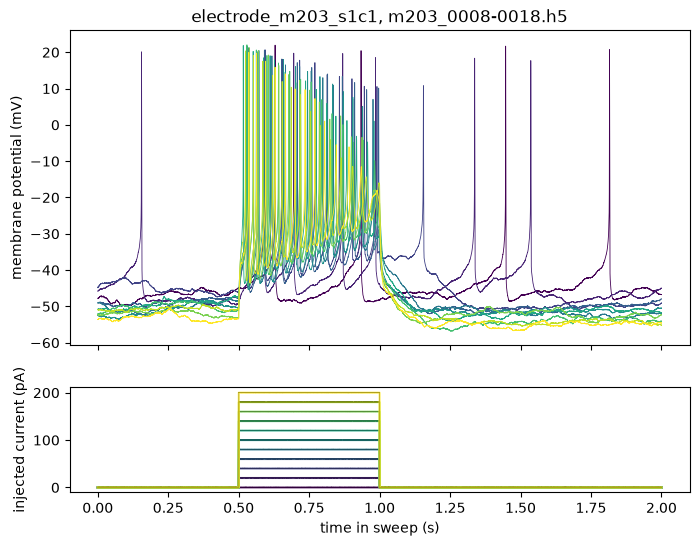

In [7]:
first_cell = runs["electrode"].iloc[0]
fi_run = runs[(runs["electrode"] == first_cell) & runs["stimulus_type"].str.contains("20 pA steps")].iloc[0]
sweeps = get_sweeps(nwbfile, fi_run["source_file"])

figure, (response_axis, stimulus_axis) = plt.subplots(2, 1, figsize=(8, 6), sharex=True, height_ratios=[3, 1])
colors = plt.cm.viridis(np.linspace(0, 1, len(sweeps)))
for (response, stimulus_template, recorded_stimulus), color in zip(sweeps, colors):
    time, voltage = to_physical_units(response)
    _, current = to_physical_units(stimulus_template)
    _, recorded_current = to_physical_units(recorded_stimulus)
    sweep_time = time - time[0]
    response_axis.plot(sweep_time, voltage * 1e3, color=color, linewidth=0.6)
    stimulus_axis.plot(sweep_time, recorded_current * 1e12, color="black", linewidth=0.5)
    stimulus_axis.plot(sweep_time, current * 1e12, color=color, linewidth=1.5, alpha=0.7)
response_axis.set_ylabel("membrane potential (mV)")
stimulus_axis.set_ylabel("injected current (pA)")
stimulus_axis.set_xlabel("time in sweep (s)")
response_axis.set_title(f"{first_cell}, {fi_run['source_file']}")
plt.show()

## F-I curves across files: CeA-SNL cells, stress vs. naive

This loops over every P70 day (the P40 mice are the only ones with a subject age, so days with `subject.age` set are skipped), selects the CeA-SNL cells by their `projection_target` column and groups them by their `stress_group` column, counts spikes in each F-I sweep, and averages the runs of each cell. Spikes are upward crossings of 0 mV during the 500 ms step, as in the preprint methods, without the 5 ms minimum interval the preprint applied through ipfx. The result approximates the CeA-SNL F-I panel of Figure 2; it is not the lab's analysis.

In [8]:
def count_spikes(voltage, time, start, stop, threshold=0.0):
    in_step = (time >= start) & (time < stop)
    above = voltage[in_step] > threshold
    return int(np.sum(above[1:] & ~above[:-1]))


rows = []
for nwbfile_path in sorted(output_dir_path.glob("sub-*.nwb")):
    with NWBHDF5IO(nwbfile_path, mode="r") as day_io:
        day = day_io.read()
        if day.subject.age is not None:
            continue  # P70 days only; the P40 mice have an age
        day_cells = day.intracellular_recordings.category_tables["electrodes"].to_dataframe()
        day_cells["electrode"] = [electrode.name for electrode in day_cells["electrode"]]
        day_cells = day_cells.drop_duplicates("electrode").set_index("electrode")
        snl_cells = day_cells[day_cells["projection_target"] == "SNL"]
        day_runs = day.get_icephys_sequential_recordings().to_dataframe()
        for source_file in day_runs.loc[day_runs["stimulus_type"].str.contains("20 pA steps"), "source_file"]:
            for response, stimulus_template, _ in get_sweeps(day, source_file):
                if response.electrode.name not in snl_cells.index:
                    continue
                time, voltage = to_physical_units(response)
                _, current = to_physical_units(stimulus_template)
                sweep_time = time - time[0]
                rows.append(
                    dict(
                        subject=day.subject.subject_id,
                        cell=response.electrode.name,
                        stress=snl_cells.loc[response.electrode.name, "stress_group"],
                        current_pA=round(float(current.max() * 1e12)),
                        firing_rate_Hz=count_spikes(voltage, sweep_time, 0.5, 1.0) / 0.5,
                    )
                )

fi = pd.DataFrame(rows)
per_cell = fi.groupby(["stress", "subject", "cell", "current_pA"], as_index=False)["firing_rate_Hz"].mean()
per_cell.groupby("stress")["cell"].nunique()

stress
naive     31
stress    31
Name: cell, dtype: int64

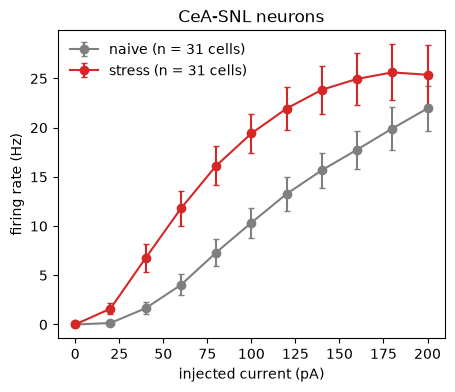

In [9]:
figure, axis = plt.subplots(figsize=(5, 4))
for stress, color in [("naive", "tab:gray"), ("stress", "tab:red")]:
    group = per_cell[per_cell["stress"] == stress].groupby("current_pA")["firing_rate_Hz"]
    mean, sem = group.mean(), group.sem()
    axis.errorbar(mean.index, mean, yerr=sem, color=color, marker="o", capsize=2, label=f"{stress} (n = {per_cell[per_cell['stress'] == stress]['cell'].nunique()} cells)")
axis.set_xlabel("injected current (pA)")
axis.set_ylabel("firing rate (Hz)")
axis.set_title("CeA-SNL neurons")
axis.legend(frameon=False)
plt.show()

In [10]:
io.close()

## Further reading

- PyNWB intracellular electrophysiology tutorial: https://pynwb.readthedocs.io/en/stable/tutorials/domain/plot_icephys.html
- Conversion notes and open questions: `nadel_2026_notes.md`, `nadel_2026_lab_questions.md`, and `nadel_2026_curator_questions.md` in `src/lerner_lab_to_nwb/nadel_2026/`